In [402]:
# =============================================
# STEP 1: IMPORT REQUIRED LIBRARIES
# =============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Data Splitting and Cross Validation
from sklearn.model_selection import (
    train_test_split,
    KFold,
    GridSearchCV,
    cross_val_score
)

# Machine Learning Models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor

# Feature Scaling
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Model Evaluation
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

import warnings
warnings.filterwarnings("ignore")

# Plot Settings
sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (8, 6)
plt.rcParams["font.size"] = 11

# Reproducibility
RANDOM_STATE = 42

print("All libraries imported successfully!")

All libraries imported successfully!


In [403]:
# File path
file_path = r"D:\MSC THESIS AAVAS\AFTER MID DEFENSE\Vehicle Class wise\Medium Vehicle_165.xlsx"

# Load dataset
df = pd.read_excel(file_path)

# Display dataset dimensions
print("Dataset Shape:", df.shape)

# Display first five rows
display(df.head())

Dataset Shape: (165, 10)


,SN,V85 Speed,Gradient,Radius of Curve,Carriageway Width,Left Shoulder Width,Left Shoulder Type,Right Shoulder Width,Right Shoulder Type,IRI
0,1,58.30,1.27,inf,5.5,0.9,Gravel,0.9,Gravel,3.70
1,2,32.60,2.92,46.0,5.5,0.9,Gravel,0.9,Gravel,4.51
2,3,41.30,7.97,inf,5.5,0.9,Gravel,0.9,Gravel,4.39
3,4,50.85,2.07,inf,5.5,0.9,Gravel,0.9,Gravel,4.69
4,5,35.00,1.21,16.0,5.5,0.9,Gravel,0.9,Gravel,5.57


In [404]:
# Dataset information
df.info()

# Check data types
print("\nData Types:")
print(df.dtypes)

<class 'pandas.DataFrame'>
RangeIndex: 165 entries, 0 to 164
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   SN                    165 non-null    int64  
 1   V85 Speed             165 non-null    float64
 2   Gradient              165 non-null    float64
 3   Radius of Curve       165 non-null    float64
 4   Carriageway Width     165 non-null    float64
 5   Left Shoulder Width   165 non-null    float64
 6   Left Shoulder Type    165 non-null    str    
 7   Right Shoulder Width  165 non-null    float64
 8   Right Shoulder Type   165 non-null    str    
 9   IRI                   165 non-null    float64
dtypes: float64(7), int64(1), str(2)
memory usage: 13.0 KB

Data Types:
SN                        int64
V85 Speed               float64
Gradient                float64
Radius of Curve         float64
Carriageway Width       float64
Left Shoulder Width     float64
Left Shoulder Type          st

In [405]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values:
SN                      0
V85 Speed               0
Gradient                0
Radius of Curve         0
Carriageway Width       0
Left Shoulder Width     0
Left Shoulder Type      0
Right Shoulder Width    0
Right Shoulder Type     0
IRI                     0
dtype: int64

Total Missing Values: 0


In [406]:
# Select numeric columns
numeric_df = df.select_dtypes(include=[np.number])

# Check infinite values
print("Infinite Values in Each Column:")
print(np.isinf(numeric_df).sum())

Infinite Values in Each Column:
SN                       0
V85 Speed                0
Gradient                 0
Radius of Curve         45
Carriageway Width        0
Left Shoulder Width      0
Right Shoulder Width     0
IRI                      0
dtype: int64


In [407]:
# Identify the curve radius column
radius_col = [col for col in df.columns if "radius" in col.lower()][0]

print("Radius Column:", radius_col)

# Convert radius values to numeric
radius_values = (
    df[radius_col]
    .astype("string")
    .str.strip()
    .str.replace(",", "", regex=False)
    .str.replace("∞", "inf", regex=False)
    .str.replace(r"(?i)^infinity$", "inf", regex=True)
)

df[radius_col] = pd.to_numeric(radius_values, errors="coerce")

# Count infinite values
print("Number of Infinite Radius Values:",
      np.isposinf(df[radius_col]).sum())

# Check missing values
print("Missing Radius Values:",
      df[radius_col].isna().sum())

Radius Column: Radius of Curve
Number of Infinite Radius Values: 45
Missing Radius Values: 0


In [408]:
# Replace positive infinity with 1500 m
df[radius_col] = df[radius_col].replace(np.inf, 1500)

print("Infinite Radius Values After Replacement:",
      np.isinf(df[radius_col]).sum())

Infinite Radius Values After Replacement: 0


In [409]:
print("Available Columns:")

for col in df.columns:
    print(col)

Available Columns:
SN
V85 Speed
Gradient
Radius of Curve
Carriageway Width
Left Shoulder Width
Left Shoulder Type
Right Shoulder Width
Right Shoulder Type
IRI


In [410]:
# Function to identify columns
def find_column(keywords):
    matches = [
        col for col in df.columns
        if all(word in col.lower() for word in keywords)
    ]

    if not matches:
        raise ValueError(
            f"Column not found for keywords: {keywords}"
        )

    return matches[0]


# Identify independent variables
gradient_col = find_column(["gradient"])
radius_col = find_column(["radius"])
carriageway_col = find_column(["carriageway", "width"])
iri_col = find_column(["iri"])

left_shoulder_col = find_column(["left", "shoulder"])
right_shoulder_col = find_column(["right", "shoulder"])

# Display selected variables
original_features = [
    gradient_col,
    radius_col,
    carriageway_col,
    left_shoulder_col,
    right_shoulder_col,
    iri_col
]

print("Original Independent Variables:")

for feature in original_features:
    print(feature)

Original Independent Variables:
Gradient
Radius of Curve
Carriageway Width
Left Shoulder Width
Right Shoulder Width
IRI


In [411]:
# =============================================
# VIF ANALYSIS FOR ALL INDEPENDENT VARIABLES
# MEDIUM VEHICLE
# =============================================

import numpy as np
import pandas as pd

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Copy original dataset
df_vif = df.copy()

# Exclude zero-speed observations
df_vif = df_vif[df_vif["V85 Speed"] > 0].copy()

# Replace infinity radius with 1500 m
df_vif["Radius of Curve"] = pd.to_numeric(
    df_vif["Radius of Curve"].replace(
        ["infinity", "Infinity", "∞", "inf", np.inf, -np.inf],
        1500
    ),
    errors="coerce"
)

# Clean shoulder type categories
df_vif["Left Shoulder Type"] = (
    df_vif["Left Shoulder Type"].astype(str).str.strip()
)

df_vif["Right Shoulder Type"] = (
    df_vif["Right Shoulder Type"].astype(str).str.strip()
)

# Select all original independent variables
X_vif = df_vif[
    [
        "Gradient",
        "Radius of Curve",
        "Carriageway Width",
        "Left Shoulder Width",
        "Left Shoulder Type",
        "Right Shoulder Width",
        "Right Shoulder Type",
        "IRI"
    ]
].copy()

# Convert categorical variables into dummy variables
X_vif = pd.get_dummies(
    X_vif,
    columns=[
        "Left Shoulder Type",
        "Right Shoulder Type"
    ],
    drop_first=True,
    dtype=int
)

# Convert all predictors to numeric
X_vif = X_vif.apply(pd.to_numeric, errors="coerce")

# Check invalid values
print("Missing Values Before VIF:")
print(X_vif.isnull().sum())

# Exclude rows with invalid predictor values
X_vif = X_vif.replace(
    [np.inf, -np.inf], np.nan
).dropna()

# Add constant for VIF calculation
X_vif_const = add_constant(X_vif, has_constant="add")

# Calculate VIF
vif_data = pd.DataFrame()

vif_data["Variable"] = X_vif.columns

vif_data["VIF"] = [
    variance_inflation_factor(
        X_vif_const.values.astype(float),
        i
    )
    for i in range(1, X_vif_const.shape[1])
]

# Sort by highest VIF
vif_data = vif_data.sort_values(
    by="VIF",
    ascending=False
).reset_index(drop=True)

print("\nVIF Analysis - All Independent Variables (Medium Vehicle)")

display(vif_data.round(3))

Missing Values Before VIF:
Gradient                      0
Radius of Curve               0
Carriageway Width             0
Left Shoulder Width           0
Right Shoulder Width          0
IRI                           0
Left Shoulder Type_Gravel     0
Left Shoulder Type_Paved      0
Right Shoulder Type_Gravel    0
Right Shoulder Type_Paved     0
dtype: int64

VIF Analysis - All Independent Variables (Medium Vehicle)


,Variable,VIF
0,Left Shoulder Type_Gravel,8.843
1,Left Shoulder Type_Paved,8.470
2,Right Shoulder Type_Paved,7.858
3,Left Shoulder Width,7.359
4,Right Shoulder Type_Gravel,6.547
5,Right Shoulder Width,5.800
6,IRI,1.829
7,Carriageway Width,1.259
8,Gradient,1.129
9,Radius of Curve,1.111


In [412]:
# =============================================
# VIF ANALYSIS WITH AVERAGE SHOULDER WIDTH
# MEDIUM VEHICLE
# =============================================

import pandas as pd
import numpy as np

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Copy dataset
df_clean = df.copy()

# Exclude zero-speed observations
df_clean = df_clean[df_clean["V85 Speed"] > 0].copy()

# Replace infinity radius with 1500 m
df_clean["Radius of Curve"] = pd.to_numeric(
    df_clean["Radius of Curve"].replace(
        ["infinity", "Infinity", "∞", "inf", np.inf, -np.inf],
        1500
    ),
    errors="coerce"
)

# Calculate Average Shoulder Width
df_clean["Average Shoulder Width"] = (
    df_clean["Left Shoulder Width"] +
    df_clean["Right Shoulder Width"]
) / 2

# Select five independent variables
features = [
    "Gradient",
    "Radius of Curve",
    "Carriageway Width",
    "Average Shoulder Width",
    "IRI"
]

X_vif = df_clean[features].copy()

# Check missing values
print("Missing Values:")
print(X_vif.isnull().sum())

# Remove rows with missing or infinite predictor values
X_vif = X_vif.replace([np.inf, -np.inf], np.nan).dropna()

# Add intercept
X_vif_const = add_constant(X_vif, has_constant="add")

# Calculate VIF
vif_data = pd.DataFrame()

vif_data["Variable"] = features

vif_data["VIF"] = [
    variance_inflation_factor(
        X_vif_const.values.astype(float), i
    )
    for i in range(1, X_vif_const.shape[1])
]

# Sort by VIF
vif_data = vif_data.sort_values(
    by="VIF",
    ascending=False
).reset_index(drop=True)

print("VIF Analysis with Average Shoulder Width - Medium Vehicle")

display(vif_data.round(3))

Missing Values:
Gradient                  0
Radius of Curve           0
Carriageway Width         0
Average Shoulder Width    0
IRI                       0
dtype: int64
VIF Analysis with Average Shoulder Width - Medium Vehicle


,Variable,VIF
0,IRI,1.758
1,Average Shoulder Width,1.553
2,Carriageway Width,1.146
3,Gradient,1.073
4,Radius of Curve,1.064


In [413]:
# =============================================
# STEP 4: FINAL FEATURE SELECTION
# MEDIUM VEHICLE
# =============================================

import numpy as np
import pandas as pd

# Define the final independent variables
features = [
    "Gradient",
    "Radius of Curve",
    "Carriageway Width",
    "Average Shoulder Width",
    "IRI"
]

# Define the dependent variable
target = "V85 Speed"

# Create final modeling dataset
df_model = df_clean[
    ["SN"] + features + [target]
].copy()

# Define independent variables (X)
X = df_model[features]

# Define dependent variable (y)
y = df_model[target]

# Display dataset information
print("FINAL FEATURE SELECTION - MEDIUM VEHICLE")
print("=" * 50)

print("\nSelected Independent Variables:")
print(X.columns.tolist())

print("\nDependent Variable:")
print(target)

print("\nTotal Observations:", len(df_model))
print("Number of Independent Variables:", X.shape[1])

print("\nFinal Modeling Dataset:")
display(df_model.head())

# Check missing and infinite values
assert X.notna().all().all(), "Missing predictor values found"
assert np.isfinite(X.to_numpy(dtype=float)).all(), "Invalid predictor values found"

assert y.notna().all(), "Missing target values found"
assert np.isfinite(y.to_numpy(dtype=float)).all(), "Invalid target values found"

# Verify positive operating speeds
assert (y > 0).all(), "Zero or negative V85 speed values found"

print("\nFinal dataset validation completed successfully.")

FINAL FEATURE SELECTION - MEDIUM VEHICLE

Selected Independent Variables:
['Gradient', 'Radius of Curve', 'Carriageway Width', 'Average Shoulder Width', 'IRI']

Dependent Variable:
V85 Speed

Total Observations: 165
Number of Independent Variables: 5

Final Modeling Dataset:


,SN,Gradient,Radius of Curve,Carriageway Width,Average Shoulder Width,IRI,V85 Speed
0,1,1.27,1500.0,5.5,0.9,3.70,58.30
1,2,2.92,46.0,5.5,0.9,4.51,32.60
2,3,7.97,1500.0,5.5,0.9,4.39,41.30
3,4,2.07,1500.0,5.5,0.9,4.69,50.85
4,5,1.21,16.0,5.5,0.9,5.57,35.00



Final dataset validation completed successfully.


In [414]:
# =============================================
# STEP 5: DESCRIPTIVE STATISTICAL ANALYSIS
# MEDIUM VEHICLE
# =============================================

import pandas as pd
import numpy as np

# Select variables for descriptive analysis
variables = features + [target]

# Calculate descriptive statistics
descriptive_stats = df_model[variables].describe().T

# Rename columns
descriptive_stats = descriptive_stats.rename(columns={
    "count": "Count",
    "mean": "Mean",
    "std": "Std. Deviation",
    "min": "Minimum",
    "25%": "25th Percentile",
    "50%": "Median",
    "75%": "75th Percentile",
    "max": "Maximum"
})

# Display results
print("DESCRIPTIVE STATISTICS - MEDIUM VEHICLE")
print("=" * 60)

display(descriptive_stats.round(3))

DESCRIPTIVE STATISTICS - MEDIUM VEHICLE


,Count,Mean,Std. Deviation,Minimum,25th Percentile,Median,75th Percentile,Maximum
Gradient,165.0,4.100955,2.498089,0.07,1.85,4.09,6.0,11.085
Radius of Curve,165.0,466.224242,638.305248,15.0,35.0,75.0,1500.0,1500.0
Carriageway Width,165.0,6.323788,0.894131,4.7,5.5,7.0,7.0,8.0
Average Shoulder Width,165.0,0.625576,0.348478,0.0,0.25,0.615,1.0,1.03
IRI,165.0,5.922667,2.636332,2.15,3.7,5.35,8.34,12.05
V85 Speed,165.0,44.657879,10.291097,24.0,37.5,44.0,51.2,70.05


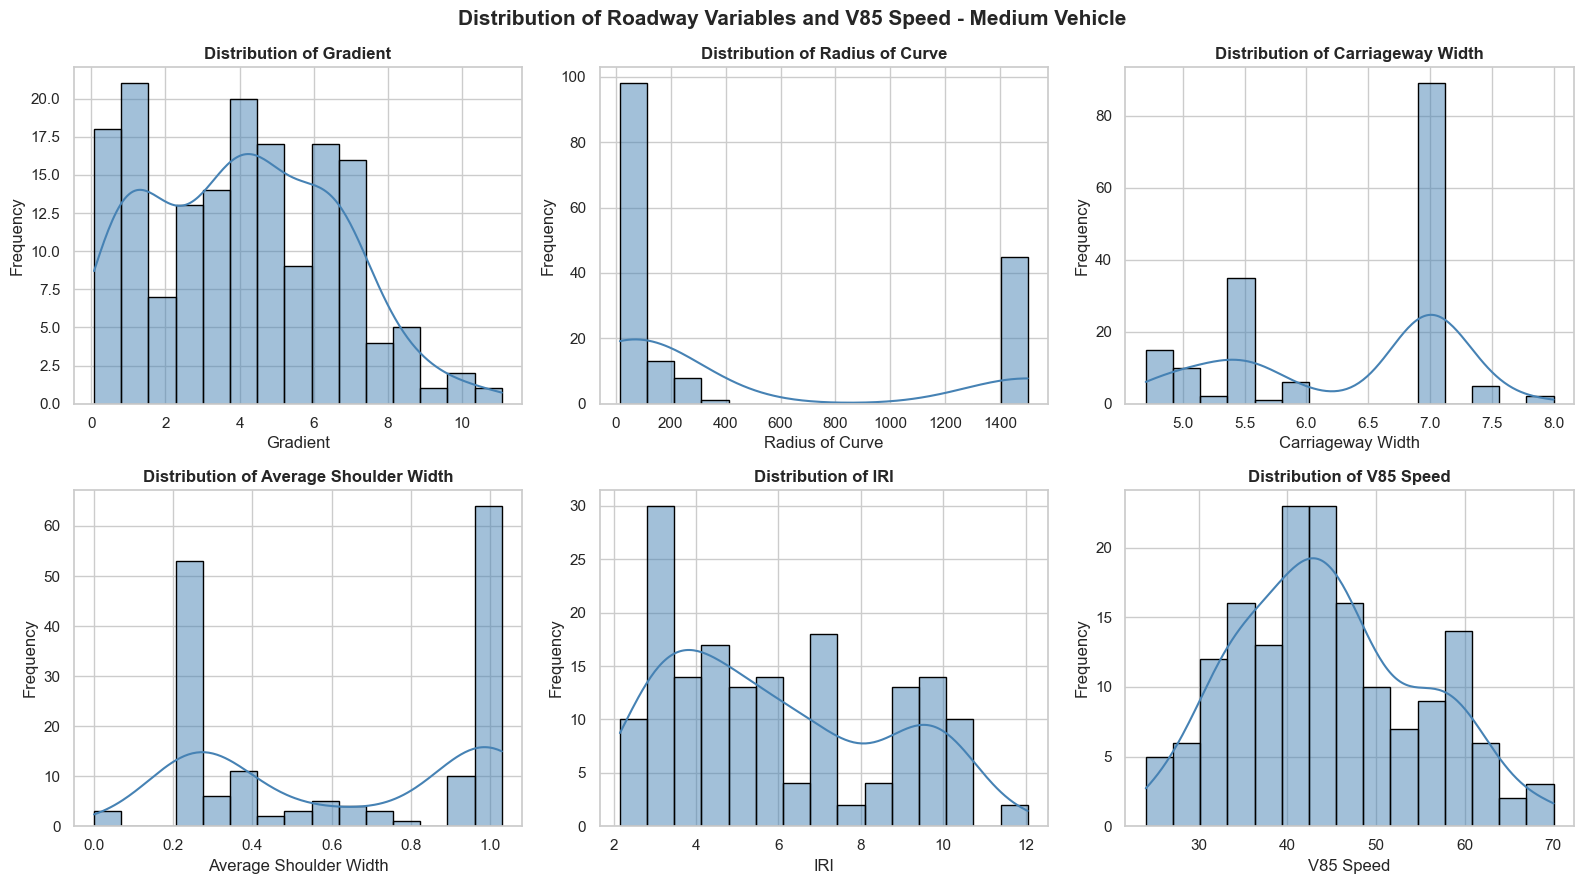

In [415]:
# =============================================
# STEP 6.1: DISTRIBUTION PLOTS
# MEDIUM VEHICLE
# =============================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

sns.set_theme(style="whitegrid")

# Variables for EDA
variables = features + [target]

# Create distribution plots
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

axes = axes.flatten()

for i, col in enumerate(variables):

    sns.histplot(
        data=df_model,
        x=col,
        kde=True,
        bins=15,
        color="steelblue",
        edgecolor="black",
        ax=axes[i]
    )

    axes[i].set_title(
        f"Distribution of {col}",
        fontsize=12,
        fontweight="bold"
    )

    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

plt.suptitle(
    "Distribution of Roadway Variables and V85 Speed - Medium Vehicle",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
# =============================================
# STEP 6.2: BOX PLOTS
# MEDIUM VEHICLE
# =============================================

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

axes = axes.flatten()

for i, col in enumerate(variables):

    sns.boxplot(
        y=df_model[col],
        color="skyblue",
        width=0.4,
        ax=axes[i]
    )

    axes[i].set_title(
        f"Box Plot of {col}",
        fontsize=12,
        fontweight="bold"
    )

    axes[i].set_ylabel(col)

plt.suptitle(
    "Box Plots of Roadway Variables and V85 Speed - Medium Vehicle",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
# =============================================
# STEP 6.3: SKEWNESS ANALYSIS
# MEDIUM VEHICLE
# =============================================

# Calculate skewness
skewness = df_model[variables].skew()

# Create skewness table
skewness_table = pd.DataFrame({
    "Variable": skewness.index,
    "Skewness": skewness.values
})

# Classify skewness
def classify_skewness(value):

    if abs(value) < 0.5:
        return "Approximately Symmetric"

    elif abs(value) < 1:
        return "Moderately Skewed"

    else:
        return "Highly Skewed"

skewness_table["Interpretation"] = (
    skewness_table["Skewness"].apply(classify_skewness)
)

print("SKEWNESS ANALYSIS - MEDIUM VEHICLE")

display(skewness_table.round(3))

In [ ]:
# =============================================
# STEP 6.4: CORRELATION MATRIX
# MEDIUM VEHICLE
# =============================================

# Calculate Pearson correlation matrix
correlation_matrix = df_model[variables].corr(
    method="pearson"
)

print("PEARSON CORRELATION MATRIX - MEDIUM VEHICLE")

display(correlation_matrix.round(3))

In [ ]:
# =============================================
# CORRELATION HEATMAP
# =============================================

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Pearson Correlation Coefficient"}
)

plt.title(
    "Correlation Matrix of Roadway Variables and V85 Speed - Medium Vehicle",
    fontsize=14,
    fontweight="bold",
    pad=15
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
# =============================================
# CORRELATION WITH V85 SPEED
# =============================================

speed_correlation = (
    correlation_matrix["V85 Speed"]
    .drop("V85 Speed")
    .sort_values(ascending=False)
)

correlation_table = pd.DataFrame({
    "Variable": speed_correlation.index,
    "Pearson Correlation": speed_correlation.values
})

print("CORRELATION WITH V85 SPEED - MEDIUM VEHICLE")

display(correlation_table.round(3))

In [ ]:
# =============================================
# STEP 6.5: RELATIONSHIP PLOTS
# MEDIUM VEHICLE
# =============================================

# Independent variables
predictors = [
    "Gradient",
    "Radius of Curve",
    "Carriageway Width",
    "Average Shoulder Width",
    "IRI"
]

fig, axes = plt.subplots(2, 3, figsize=(17, 10))

axes = axes.flatten()

for i, col in enumerate(predictors):

    sns.regplot(
        data=df_model,
        x=col,
        y="V85 Speed",
        scatter_kws={
            "alpha": 0.6,
            "s": 45,
            "color": "steelblue"
        },
        line_kws={
            "color": "red",
            "linewidth": 2
        },
        ax=axes[i]
    )

    axes[i].set_title(
        f"{col} vs V85 Speed",
        fontsize=12,
        fontweight="bold"
    )

    axes[i].set_xlabel(col)
    axes[i].set_ylabel("V85 Speed (km/h)")

# Remove unused subplot
fig.delaxes(axes[5])

plt.suptitle(
    "Relationship Between Roadway Variables and V85 Speed - Medium Vehicle",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
# =============================================
# STEP 7.1: TRAIN-TEST SPLITTING
# MEDIUM VEHICLE
# =============================================

from sklearn.model_selection import train_test_split

# Define independent variables
X = df_model[features]

# Define dependent variable
y = df_model["V85 Speed"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Display splitting information
print("TRAIN-TEST SPLITTING - MEDIUM VEHICLE")
print("=" * 50)

print("Total Observations:", len(X))
print("Training Observations:", len(X_train))
print("Testing Observations:", len(X_test))

print("\nTraining Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

In [ ]:
# =============================================
# FIVE-FOLD CROSS-VALIDATION
# MEDIUM VEHICLE
# =============================================

from sklearn.model_selection import KFold

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Five-fold cross-validation initialized.")

In [ ]:
# =============================================
# STEP 8.1: MULTIPLE LINEAR REGRESSION
# MEDIUM VEHICLE
# =============================================

from sklearn.linear_model import LinearRegression

# Initialize MLR model
mlr_model = LinearRegression()

# Train the model
mlr_model.fit(X_train, y_train)

# Make predictions
y_train_pred_mlr = mlr_model.predict(X_train)
y_test_pred_mlr = mlr_model.predict(X_test)

print("MLR Model Training Completed Successfully.")

In [ ]:
# =============================================
# STEP 8.2: MLR MODEL EVALUATION
# MEDIUM VEHICLE
# =============================================

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

# Training performance
train_r2_mlr = r2_score(y_train, y_train_pred_mlr)

train_rmse_mlr = np.sqrt(
    mean_squared_error(y_train, y_train_pred_mlr)
)

train_mae_mlr = mean_absolute_error(
    y_train, y_train_pred_mlr
)

# Testing performance
test_r2_mlr = r2_score(y_test, y_test_pred_mlr)

test_rmse_mlr = np.sqrt(
    mean_squared_error(y_test, y_test_pred_mlr)
)

test_mae_mlr = mean_absolute_error(
    y_test, y_test_pred_mlr
)

# Display results
print("MLR MODEL PERFORMANCE - MEDIUM VEHICLE")
print("=" * 55)

print("\nTraining Performance:")
print(f"R²   : {train_r2_mlr:.4f}")
print(f"RMSE : {train_rmse_mlr:.4f} km/h")
print(f"MAE  : {train_mae_mlr:.4f} km/h")

print("\nTesting Performance:")
print(f"R²   : {test_r2_mlr:.4f}")
print(f"RMSE : {test_rmse_mlr:.4f} km/h")
print(f"MAE  : {test_mae_mlr:.4f} km/h")

In [ ]:
# =============================================
# STEP 8.3: MLR REGRESSION COEFFICIENTS
# MEDIUM VEHICLE
# =============================================

# Create coefficient table
mlr_coefficients = pd.DataFrame({
    "Variable": features,
    "Coefficient": mlr_model.coef_
})

# Display intercept
print("MLR Intercept:", round(mlr_model.intercept_, 4))

print("\nMLR Regression Coefficients:")

display(mlr_coefficients.round(4))

In [ ]:
# =============================================
# STEP 8.4: MLR PREDICTION EQUATION
# =============================================

equation = f"V85 = {mlr_model.intercept_:.4f}"

for feature, coef in zip(features, mlr_model.coef_):
    sign = "+" if coef >= 0 else "-"
    equation += f" {sign} {abs(coef):.4f} × ({feature})"

print("MLR PREDICTION EQUATION - MEDIUM VEHICLE")
print("=" * 60)

print(equation)

In [ ]:
# =============================================
# STEP 8.5: MODEL PERFORMANCE COMPARISON
# =============================================

# Initialize model results
model_results = []

# Store MLR results
model_results.append({
    "Model": "MLR",
    "Train R²": train_r2_mlr,
    "Test R²": test_r2_mlr,
    "Train RMSE": train_rmse_mlr,
    "Test RMSE": test_rmse_mlr,
    "Train MAE": train_mae_mlr,
    "Test MAE": test_mae_mlr
})

# Create comparison table
comparison_df = pd.DataFrame(model_results)

print("MODEL PERFORMANCE COMPARISON - MEDIUM VEHICLE")

display(comparison_df.round(4))

In [ ]:
# =============================================
# STEP 9.2: RANDOM FOREST HYPERPARAMETER GRID
# MEDIUM VEHICLE
# =============================================

param_grid_rf = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 5, 10, 15],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

In [ ]:
# =============================================
# STEP 9.3: HYPERPARAMETER TUNING
# RANDOM FOREST - MEDIUM VEHICLE
# =============================================

# Initialize Random Forest
rf = RandomForestRegressor(
    random_state=42
)

# GridSearchCV
grid_rf = GridSearchCV(
    estimator=rf,
    param_grid=param_grid_rf,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1
)

# Train using training dataset only
grid_rf.fit(X_train, y_train)

# Best tuned model
best_rf = grid_rf.best_estimator_

# Display best parameters
print("TUNED RANDOM FOREST - MEDIUM VEHICLE")
print("=" * 55)

print("\nBest Hyperparameters:")
print(grid_rf.best_params_)

print("\nBest Cross-Validation RMSE:")
print(f"{-grid_rf.best_score_:.4f} km/h")

In [ ]:
# =============================================
# STEP 9.4: RANDOM FOREST PREDICTIONS
# =============================================

# Training predictions
y_train_pred_rf = best_rf.predict(X_train)

# Testing predictions
y_test_pred_rf = best_rf.predict(X_test)

print("Tuned Random Forest Predictions Completed.")

In [ ]:
# =============================================
# STEP 9.5: RANDOM FOREST MODEL EVALUATION
# MEDIUM VEHICLE
# =============================================

# Training performance
train_r2_rf = r2_score(
    y_train, y_train_pred_rf
)

train_rmse_rf = np.sqrt(
    mean_squared_error(y_train, y_train_pred_rf)
)

train_mae_rf = mean_absolute_error(
    y_train, y_train_pred_rf
)

# Testing performance
test_r2_rf = r2_score(
    y_test, y_test_pred_rf
)

test_rmse_rf = np.sqrt(
    mean_squared_error(y_test, y_test_pred_rf)
)

test_mae_rf = mean_absolute_error(
    y_test, y_test_pred_rf
)

# Display results
print("TUNED RANDOM FOREST PERFORMANCE - MEDIUM VEHICLE")
print("=" * 60)

print("\nTraining Performance:")
print(f"R²   : {train_r2_rf:.4f}")
print(f"RMSE : {train_rmse_rf:.4f} km/h")
print(f"MAE  : {train_mae_rf:.4f} km/h")

print("\nTesting Performance:")
print(f"R²   : {test_r2_rf:.4f}")
print(f"RMSE : {test_rmse_rf:.4f} km/h")
print(f"MAE  : {test_mae_rf:.4f} km/h")

In [ ]:
# =============================================
# STEP 9.6: UPDATE MODEL COMPARISON TABLE
# MEDIUM VEHICLE
# =============================================

# Remove previous Random Forest result
# Prevents duplicate entries when rerunning

model_results = [
    result for result in model_results
    if result["Model"] != "Tuned RF"
]

# Store updated tuned RF results
model_results.append({
    "Model": "Tuned RF",
    "Train R²": train_r2_rf,
    "Test R²": test_r2_rf,
    "Train RMSE": train_rmse_rf,
    "Test RMSE": test_rmse_rf,
    "Train MAE": train_mae_rf,
    "Test MAE": test_mae_rf
})

# Create comparison table
comparison_df = pd.DataFrame(model_results)

# Sort by testing RMSE
comparison_df = comparison_df.sort_values(
    by="Test RMSE",
    ascending=True
).reset_index(drop=True)

print("MODEL PERFORMANCE COMPARISON - MEDIUM VEHICLE")
print("=" * 65)

display(comparison_df.round(4))

In [ ]:
# =============================================
# STEP 9.7: RANDOM FOREST FEATURE IMPORTANCE
# MEDIUM VEHICLE
# =============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Extract feature importance from tuned RF model
rf_importance = best_rf.feature_importances_

# Create feature importance DataFrame
rf_feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_importance
})

# Sort features by importance
rf_feature_importance = rf_feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Display results
print("TUNED RANDOM FOREST FEATURE IMPORTANCE - MEDIUM VEHICLE")
print("=" * 60)

display(rf_feature_importance.round(4))

In [ ]:
# =============================================
# RANDOM FOREST FEATURE IMPORTANCE PLOT
# MEDIUM VEHICLE
# =============================================

plt.figure(figsize=(10, 6))

sns.barplot(
    data=rf_feature_importance,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title(
    "Feature Importance - Tuned Random Forest (Medium Vehicle)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Feature Importance Score", fontsize=12)
plt.ylabel("Roadway Characteristics", fontsize=12)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

plt.tight_layout()
plt.show()

In [ ]:
# =============================================
# STEP 10.2: XGBOOST HYPERPARAMETER GRID
# MEDIUM VEHICLE
# =============================================

param_grid_xgb = {
    "n_estimators": [100, 200],
    "max_depth": [3, 4, 5],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0]
}

In [ ]:
# =============================================
# STEP 10.3: HYPERPARAMETER TUNING
# XGBOOST - MEDIUM VEHICLE
# =============================================

# Initialize XGBoost model
xgb = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=1,
    importance_type="gain"
)

# GridSearchCV
grid_xgb = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid_xgb,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1
)

# Train using training dataset only
grid_xgb.fit(X_train, y_train)

# Best tuned model
best_xgb = grid_xgb.best_estimator_

# Display best parameters
print("TUNED XGBOOST - MEDIUM VEHICLE")
print("=" * 55)

print("\nBest Hyperparameters:")
print(grid_xgb.best_params_)

print("\nBest Cross-Validation RMSE:")
print(f"{-grid_xgb.best_score_:.4f} km/h")

In [ ]:
# =============================================
# STEP 10.4: XGBOOST PREDICTIONS
# MEDIUM VEHICLE
# =============================================

# Training predictions
y_train_pred_xgb = best_xgb.predict(X_train)

# Testing predictions
y_test_pred_xgb = best_xgb.predict(X_test)

print("Tuned XGBoost Predictions Completed.")

In [ ]:
# =============================================
# STEP 10.5: XGBOOST MODEL EVALUATION
# MEDIUM VEHICLE
# =============================================

# Training performance
train_r2_xgb = r2_score(
    y_train, y_train_pred_xgb
)

train_rmse_xgb = np.sqrt(
    mean_squared_error(y_train, y_train_pred_xgb)
)

train_mae_xgb = mean_absolute_error(
    y_train, y_train_pred_xgb
)

# Testing performance
test_r2_xgb = r2_score(
    y_test, y_test_pred_xgb
)

test_rmse_xgb = np.sqrt(
    mean_squared_error(y_test, y_test_pred_xgb)
)

test_mae_xgb = mean_absolute_error(
    y_test, y_test_pred_xgb
)

# Display results
print("TUNED XGBOOST PERFORMANCE - MEDIUM VEHICLE")
print("=" * 60)

print("\nTraining Performance:")
print(f"R²   : {train_r2_xgb:.4f}")
print(f"RMSE : {train_rmse_xgb:.4f} km/h")
print(f"MAE  : {train_mae_xgb:.4f} km/h")

print("\nTesting Performance:")
print(f"R²   : {test_r2_xgb:.4f}")
print(f"RMSE : {test_rmse_xgb:.4f} km/h")
print(f"MAE  : {test_mae_xgb:.4f} km/h")

In [ ]:
# =============================================
# STEP 10.6: XGBOOST FEATURE IMPORTANCE
# MEDIUM VEHICLE
# =============================================

# Extract feature importance
xgb_importance = best_xgb.feature_importances_

# Create feature importance DataFrame
xgb_feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb_importance
})

# Sort features by importance
xgb_feature_importance = xgb_feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Display results
print("TUNED XGBOOST FEATURE IMPORTANCE - MEDIUM VEHICLE")
print("=" * 60)

display(xgb_feature_importance.round(4))

In [ ]:
# =============================================
# XGBOOST FEATURE IMPORTANCE PLOT
# MEDIUM VEHICLE
# =============================================

plt.figure(figsize=(10, 6))

sns.barplot(
    data=xgb_feature_importance,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title(
    "Feature Importance - Tuned XGBoost (Medium Vehicle)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Feature Importance Score", fontsize=12)
plt.ylabel("Roadway Characteristics", fontsize=12)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

plt.tight_layout()
plt.show()

In [ ]:
# =============================================
# STEP 10.8: MODEL PERFORMANCE COMPARISON
# MEDIUM VEHICLE
# =============================================

# Remove previous XGBoost result if this cell is rerun
model_results = [
    result for result in model_results
    if result["Model"] != "Tuned XGBoost"
]

# Store tuned XGBoost results
model_results.append({
    "Model": "Tuned XGBoost",
    "Train R²": train_r2_xgb,
    "Test R²": test_r2_xgb,
    "Train RMSE": train_rmse_xgb,
    "Test RMSE": test_rmse_xgb,
    "Train MAE": train_mae_xgb,
    "Test MAE": test_mae_xgb
})

# Create comparison table
comparison_df = pd.DataFrame(model_results)

# Sort by testing RMSE
comparison_df = comparison_df.sort_values(
    by="Test RMSE",
    ascending=True
).reset_index(drop=True)

print("MODEL PERFORMANCE COMPARISON - MEDIUM VEHICLE")
print("=" * 65)

display(comparison_df.round(4))

In [ ]:
# =============================================
# STEP 11.2: SVR PIPELINE AND PARAMETER GRID
# MEDIUM VEHICLE
# =============================================

# Create SVR pipeline with StandardScaler
svr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR())
])

# Define hyperparameter grid
param_grid_svr = {
    "svr__C": [1, 10, 100, 1000],
    "svr__epsilon": [0.01, 0.1, 0.5, 1],
    "svr__gamma": ["scale", 0.001, 0.01, 0.1, 1],
    "svr__kernel": ["rbf"]
}

In [ ]:
# =============================================
# STEP 11.3: HYPERPARAMETER TUNING
# SVR - MEDIUM VEHICLE
# =============================================

# Initialize GridSearchCV
grid_svr = GridSearchCV(
    estimator=svr_pipeline,
    param_grid=param_grid_svr,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1
)

# Train using training dataset only
grid_svr.fit(X_train, y_train)

# Extract best tuned SVR model
best_svr = grid_svr.best_estimator_

# Display results
print("TUNED SVR - MEDIUM VEHICLE")
print("=" * 55)

print("\nBest Hyperparameters:")
print(grid_svr.best_params_)

print("\nBest Cross-Validation RMSE:")
print(f"{-grid_svr.best_score_:.4f} km/h")

In [ ]:
# =============================================
# STEP 11.4: SVR PREDICTIONS
# MEDIUM VEHICLE
# =============================================

# Training predictions
y_train_pred_svr = best_svr.predict(X_train)

# Testing predictions
y_test_pred_svr = best_svr.predict(X_test)

print("Tuned SVR Predictions Completed.")

In [ ]:
# =============================================
# STEP 11.5: SVR MODEL EVALUATION
# MEDIUM VEHICLE
# =============================================

# Training performance
train_r2_svr = r2_score(
    y_train, y_train_pred_svr
)

train_rmse_svr = np.sqrt(
    mean_squared_error(y_train, y_train_pred_svr)
)

train_mae_svr = mean_absolute_error(
    y_train, y_train_pred_svr
)

# Testing performance
test_r2_svr = r2_score(
    y_test, y_test_pred_svr
)

test_rmse_svr = np.sqrt(
    mean_squared_error(y_test, y_test_pred_svr)
)

test_mae_svr = mean_absolute_error(
    y_test, y_test_pred_svr
)

# Display results
print("TUNED SVR PERFORMANCE - MEDIUM VEHICLE")
print("=" * 60)

print("\nTraining Performance:")
print(f"R²   : {train_r2_svr:.4f}")
print(f"RMSE : {train_rmse_svr:.4f} km/h")
print(f"MAE  : {train_mae_svr:.4f} km/h")

print("\nTesting Performance:")
print(f"R²   : {test_r2_svr:.4f}")
print(f"RMSE : {test_rmse_svr:.4f} km/h")
print(f"MAE  : {test_mae_svr:.4f} km/h")

In [ ]:
# =============================================
# STEP 11.7: MODEL PERFORMANCE COMPARISON
# MEDIUM VEHICLE
# =============================================

# Remove previous SVR result if this cell is rerun
model_results = [
    result for result in model_results
    if result["Model"] != "Tuned SVR"
]

# Store tuned SVR results
model_results.append({
    "Model": "Tuned SVR",
    "Train R²": train_r2_svr,
    "Test R²": test_r2_svr,
    "Train RMSE": train_rmse_svr,
    "Test RMSE": test_rmse_svr,
    "Train MAE": train_mae_svr,
    "Test MAE": test_mae_svr
})

# Create comparison table
comparison_df = pd.DataFrame(model_results)

# Sort by testing RMSE
comparison_df = comparison_df.sort_values(
    by="Test RMSE",
    ascending=True
).reset_index(drop=True)

print("MODEL PERFORMANCE COMPARISON - MEDIUM VEHICLE")
print("=" * 65)

display(comparison_df.round(4))

In [ ]:
# =============================================
# STEP 12.2: ANN PIPELINE AND PARAMETER GRID
# MEDIUM VEHICLE
# =============================================

# Create ANN pipeline with StandardScaler
ann_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ann", MLPRegressor(
        max_iter=3000,
        random_state=42
    ))
])

# Define hyperparameter grid
param_grid_ann = {
    "ann__hidden_layer_sizes": [
        (32,), (64,), (64, 32), (128, 64)
    ],
    "ann__activation": ["relu", "tanh"],
    "ann__alpha": [0.0001, 0.001, 0.01],
    "ann__learning_rate_init": [0.001, 0.01]
}

In [ ]:
# =============================================
# STEP 12.3: HYPERPARAMETER TUNING
# ANN - MEDIUM VEHICLE
# =============================================

# Define 5-fold cross-validation
cv_ann = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Initialize GridSearchCV
grid_ann = GridSearchCV(
    estimator=ann_pipeline,
    param_grid=param_grid_ann,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1,
    refit=True
)

# Train using training dataset only
grid_ann.fit(X_train, y_train)

# Extract best tuned ANN model
best_ann = grid_ann.best_estimator_

# Display results
print("TUNED ANN - MEDIUM VEHICLE")
print("=" * 55)

print("\nBest Hyperparameters:")
print(grid_ann.best_params_)

print("\nBest Cross-Validation RMSE:")
print(f"{-grid_ann.best_score_:.4f} km/h")

In [ ]:
# =============================================
# STEP 12.4: ANN PREDICTIONS
# MEDIUM VEHICLE
# =============================================

# Training predictions
y_train_pred_ann = best_ann.predict(X_train)

# Testing predictions
y_test_pred_ann = best_ann.predict(X_test)

print("Tuned ANN Predictions Completed.")

In [ ]:
# =============================================
# STEP 12.5: ANN MODEL EVALUATION
# MEDIUM VEHICLE
# =============================================

# Training performance
train_r2_ann = r2_score(
    y_train, y_train_pred_ann
)

train_rmse_ann = np.sqrt(
    mean_squared_error(y_train, y_train_pred_ann)
)

train_mae_ann = mean_absolute_error(
    y_train, y_train_pred_ann
)

# Testing performance
test_r2_ann = r2_score(
    y_test, y_test_pred_ann
)

test_rmse_ann = np.sqrt(
    mean_squared_error(y_test, y_test_pred_ann)
)

test_mae_ann = mean_absolute_error(
    y_test, y_test_pred_ann
)

# Display results
print("TUNED ANN PERFORMANCE - MEDIUM VEHICLE")
print("=" * 60)

print("\nTraining Performance:")
print(f"R²   : {train_r2_ann:.4f}")
print(f"RMSE : {train_rmse_ann:.4f} km/h")
print(f"MAE  : {train_mae_ann:.4f} km/h")

print("\nTesting Performance:")
print(f"R²   : {test_r2_ann:.4f}")
print(f"RMSE : {test_rmse_ann:.4f} km/h")
print(f"MAE  : {test_mae_ann:.4f} km/h")

In [ ]:
# =============================================
# STEP 12.7: MODEL PERFORMANCE COMPARISON
# MEDIUM VEHICLE
# =============================================

# Remove previous ANN result if this cell is rerun
model_results = [
    result for result in model_results
    if result["Model"] != "Tuned ANN"
]

# Store tuned ANN results
model_results.append({
    "Model": "Tuned ANN",
    "Train R²": train_r2_ann,
    "Test R²": test_r2_ann,
    "Train RMSE": train_rmse_ann,
    "Test RMSE": test_rmse_ann,
    "Train MAE": train_mae_ann,
    "Test MAE": test_mae_ann
})

# Create comparison table
comparison_df = pd.DataFrame(model_results)

# Sort by testing RMSE
comparison_df = comparison_df.sort_values(
    by="Test RMSE",
    ascending=True
).reset_index(drop=True)

print("MODEL PERFORMANCE COMPARISON - MEDIUM VEHICLE")
print("=" * 65)

display(comparison_df.round(4))

In [ ]:
# =============================================
# STEP 12.8: IDENTIFY BEST MODEL
# MEDIUM VEHICLE
# =============================================

# Identify best model based on Test RMSE
best_model_result = comparison_df.loc[
    comparison_df["Test RMSE"].idxmin()
]

print("BEST PERFORMING MODEL - MEDIUM VEHICLE")
print("=" * 60)

print("Model:", best_model_result["Model"])

print(f"Testing R²   : {best_model_result['Test R²']:.4f}")
print(f"Testing RMSE : {best_model_result['Test RMSE']:.4f} km/h")
print(f"Testing MAE  : {best_model_result['Test MAE']:.4f} km/h")